# Sporulation: Noise-robust model training, and ancestral phenotype prediction

This notebook provides a pipeline for training noise robust models, and apply them for ancestral phenotype prediction.

In [1]:
import pandas as pd
import numpy as np
import torch
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from utils.utils import read_sporulat_data, tsne_plot

TAX_LEVEL = "phylum"  # <----------------------- taxonomy level for train/test split is here!!
DATA_DIRECTORY = "data_sporulation"  # <-------- input data directory is here!!
NUM_SPLITS_TO_READ = 30  # <-------------------- number of splits to read and process is here!!

RANDOM_SEED = 42
OUTPUT_DIRECTORY = f"../{DATA_DIRECTORY}/outputs/{TAX_LEVEL}"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
# Create the output directory if doesn't exist
if not os.path.exists(f"{OUTPUT_DIRECTORY}/plots"):
    os.makedirs(f"{OUTPUT_DIRECTORY}/plots")

In [3]:
# Read train/test/validation splits
from collections import defaultdict

all_splits_dict = defaultdict(int)
for split_id in range(26):
    # Read train data
    data_filename_train = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/train_data_{TAX_LEVEL}_split_{split_id}"
    y_filename_train = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/train_annot_{TAX_LEVEL}_split_{split_id}"
    taxa_names_filename_train = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/train_taxa_{TAX_LEVEL}_split_{split_id}" if TAX_LEVEL != "random" else None
    X_val_train = torch.load(data_filename_train)
    y_label_train = torch.load(y_filename_train)
    with open(taxa_names_filename_train, "r") as f:
        taxa_group_names_train = [line.strip() for line in f]
        
    # Read validation data
    data_filename_val = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/val_data_{TAX_LEVEL}_split_{split_id}"
    y_filename_val = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/val_annot_{TAX_LEVEL}_split_{split_id}"
    taxa_names_filename_val = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/val_taxa_{TAX_LEVEL}_split_{split_id}" if TAX_LEVEL != "random" else None
    X_val_val = torch.load(data_filename_val)
    y_label_val = torch.load(y_filename_val)
    with open(taxa_names_filename_val, "r") as f:
        taxa_group_names_val = [line.strip() for line in f]
        
    # Read test data
    data_filename_test = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/test_data_{TAX_LEVEL}_split_{split_id}"
    y_filename_test = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/test_annot_{TAX_LEVEL}_split_{split_id}"
    taxa_names_filename_test = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/test_taxa_{TAX_LEVEL}_split_{split_id}"  if TAX_LEVEL != "random" else None
    X_val_test = torch.load(data_filename_test)
    y_label_test = torch.load(y_filename_test)
    with open(taxa_names_filename_test, "r") as f:
        taxa_group_names_test = [line.strip() for line in f]
        
    if sum(y_label_test) == 0 or sum(y_label_train) == 0:
        continue

    if TAX_LEVEL == "random":
        taxa_group_names_train = None
        taxa_group_names_test = None

    if X_val_train is not None and y_label_train is not None and X_val_test is not None and y_label_test is not None and X_val_val is not None and y_label_val is not None:
        curr_split_dict = defaultdict(str)
        curr_split_dict["X_train"] = X_val_train
        curr_split_dict["y_train"] = y_label_train
        
        curr_split_dict["taxa_group_names_train"] = taxa_group_names_train
        curr_split_dict["X_test"] = X_val_test
        curr_split_dict["y_test"] = y_label_test
        curr_split_dict["taxa_group_names_test"] = taxa_group_names_test
        
        curr_split_dict["X_val"] = X_val_val
        curr_split_dict["y_val"] = y_label_val
        curr_split_dict["taxa_group_names_val"] = taxa_group_names_val
    
        all_splits_dict[split_id] = curr_split_dict

print(f"Number of added splits = {len(all_splits_dict.keys())}")           

Number of added splits = 26


### 2. Noize tolerance of the original model (trained on the original train data sets)

In [4]:
import joblib
from tqdm import tqdm
from xgboost import XGBClassifier
from sklearn.pipeline import make_pipeline

# Train and save models for each data split
trained_models = {}
for split_id in tqdm(all_splits_dict.keys(), desc="Training splits"):
    X_val_train = all_splits_dict[split_id]["X_train"]
    y_label_train = all_splits_dict[split_id]["y_train"]

    pipe = make_pipeline(
        make_pipeline(XGBClassifier(n_jobs=THREADS if DEVICE == "cpu" else None, tree_method="gpu_hist" if DEVICE == "cpu" else "hist"))
    )
    pipe.fit(X_val_train.cpu(), y_label_train.cpu())
    trained_models[split_id] = pipe

Training splits: 100%|██████████████████████████████████████████████████████████████████████████████████████| 26/26 [00:20<00:00,  1.28it/s]


In [5]:
# Evaluate the trained models accuracies on noisy test data

from utils.utils_ancestral_predict import eval_trained_models_on_noisy_data, plot_one_accur_measure

cog_remov_add_accuracies_orig_models = eval_trained_models_on_noisy_data(all_splits_dict, trained_models, hard_fn_flag = True, test_or_val = "test")

In [6]:
# Create the output directory for plots if it doesn't exist yet
if not os.path.exists(f"{OUTPUT_DIRECTORY}/plots"):
    os.makedirs(f"{OUTPUT_DIRECTORY}/plots")

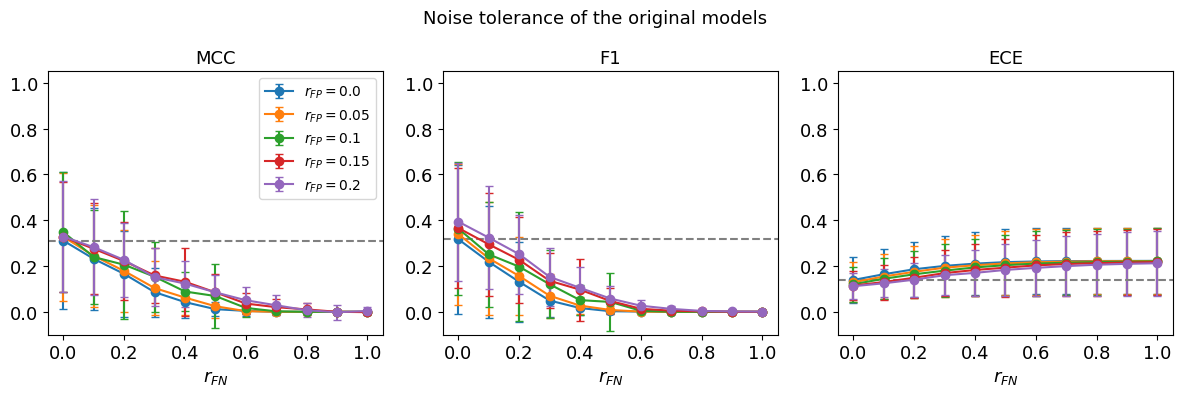

In [7]:
# Visualize the results

FONTSIZE = 13

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

metrics = [
    ("mcc", "MCC"),
    ("f1", "F1"),
    ("ece", "ECE"),
]

for ax, (metric, title) in zip(axes, metrics):

    plot_one_accur_measure(
        ax,
        metric,
        cog_remov_add_accuracies_orig_models,
        fontsize=FONTSIZE,
    )

    ax.axhline(
        y=cog_remov_add_accuracies_orig_models[(0.0, 0.0)][metric][0],
        color="grey",
        linestyle="--",
        linewidth=1.5,
    )

    ax.set_ylim([-0.1, 1.05])
    ax.set_title(title, fontsize=FONTSIZE)

axes[0].legend()

plt.suptitle(
    "Noise tolerance of the original models",
    fontsize=FONTSIZE,
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_toler_orig_models.pdf",
    format="pdf",
    bbox_inches="tight",
)
plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_toler_orig_models.svg",
    format="svg",
    bbox_inches="tight",
)

plt.show()

### 3. Noise tolerance of the models trained on noisy data

Here we train the original models for each train/test split and explore their performance on the noisy test data. The noise on the test dataset is implemented as the fraction false positives and false negatives.

In [8]:
# Create output directories for the trained models

TRAINED_MOD_DIR = "trained_models_train_val_test"
if not os.path.exists(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}"):
    os.makedirs(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}")

#### 3.1 Analyze performance of the models on the high noise range [min_fp, max_fp], [min_fn, max_fn]

Processing noise types:   0%|                                                                                                                                       | 0/3 [00:00<?, ?it/s]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  33%|██████████████████████████████████████████▎                                                                                    | 1/3 [00:02<00:04,  2.05s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  67%|████████████████████████████████████████████████████████████████████████████████████▋                                          | 2/3 [00:04<00:02,  2.20s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:07<00:00,  2.41s/it]


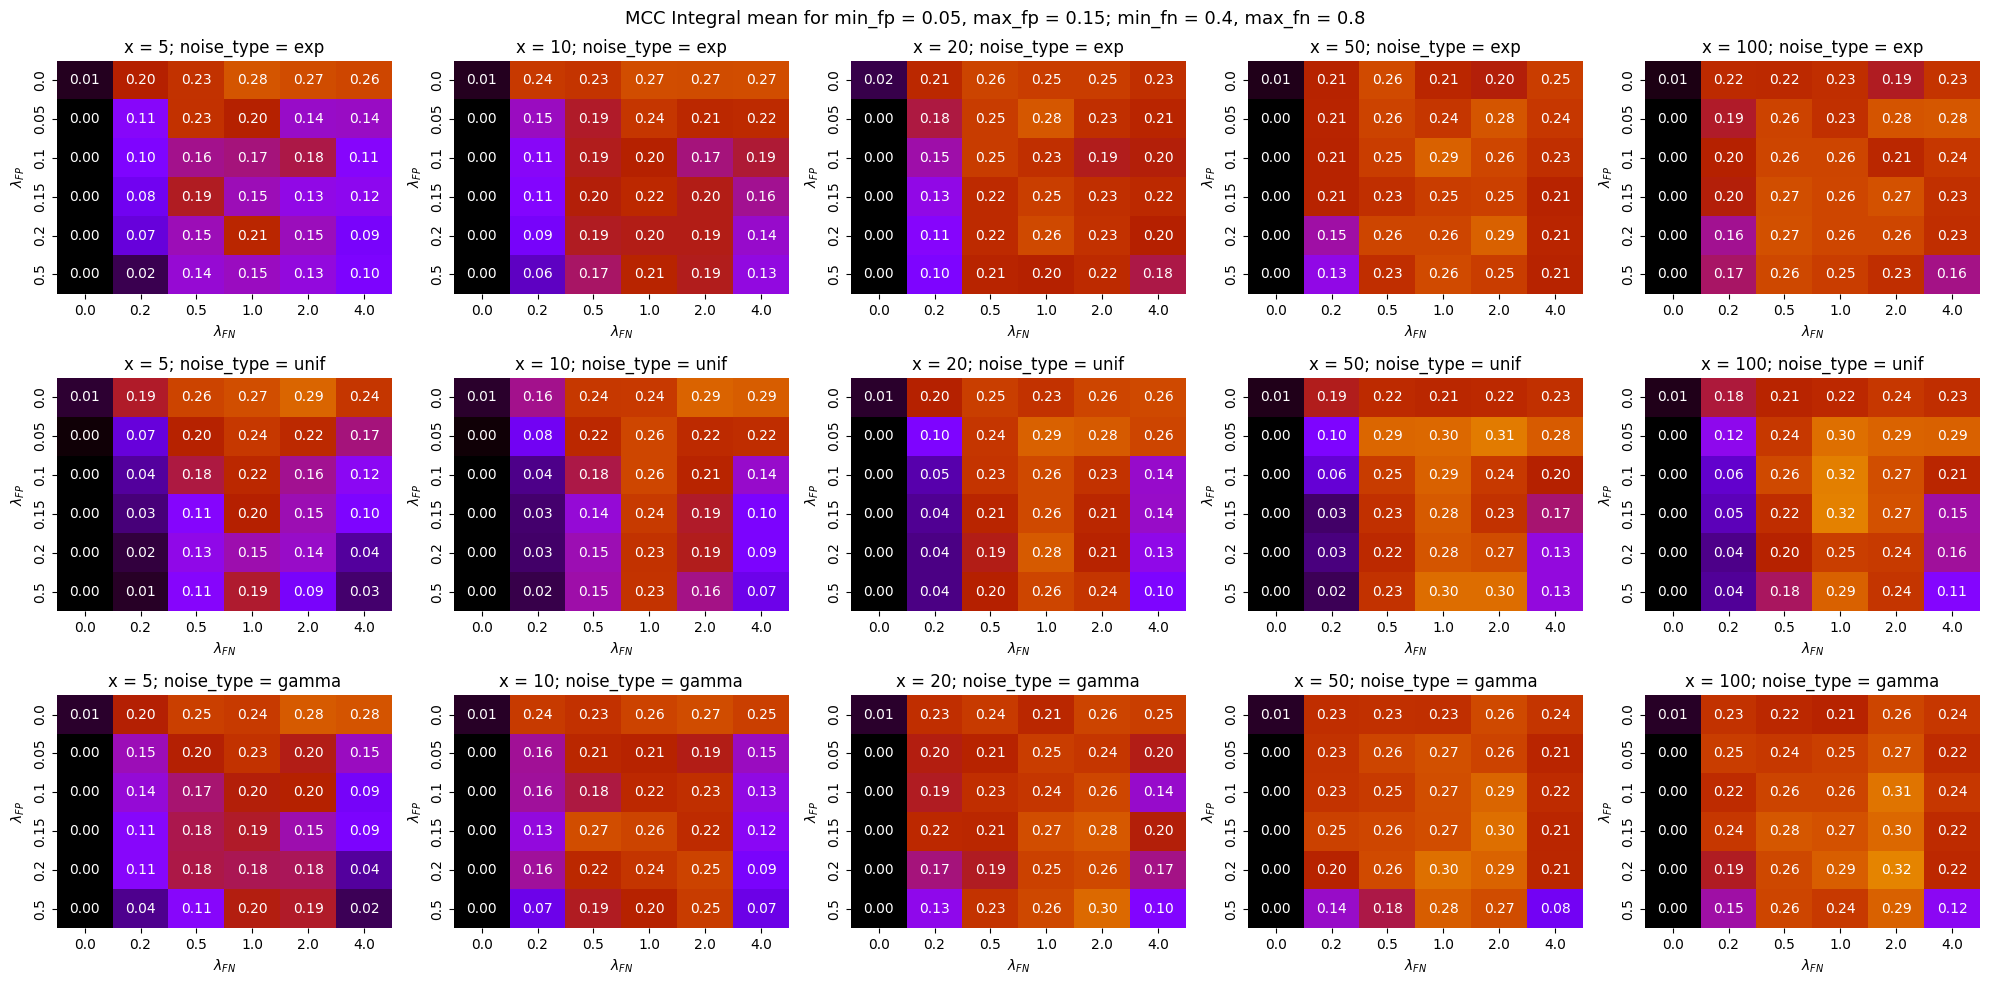

In [9]:
# Find the integrals of the MCC curves calculated for models trained on diffrent noise ranges and fisualize the result

from utils.utils_ancestral_predict import eval_trained_models_on_noisy_data, fp_curve_areas_one_model, fp_fn_surface_integral, plot_model_groups_surf_int

# Specify the noise range for the test data
fn_rate_arr = [0.0, 0.2, 0.5, 1.0, 2.0, 4.0]
fp_rate_arr = [0.0, 0.05, 0.1, 0.15, 0.2, 0.5]
mean_rem_add_rates_tuples = [(add, rem) for add in fp_rate_arr for rem in fn_rate_arr]

# Specify the min and max noise ranges for the test data (the ranges for which the integrals will be calculated)
min_fn = 0.4
max_fn = 0.8

min_fp = 0.05
max_fp = 0.15

# Specify the paraters of the models trained on noise augmented data
x_range = [5, 10, 20, 50, 100]
noise_type_range = ["exp", "unif", "gamma"]

# Calculate the integrals for each trained model and visualize the result
fig, axes = plt.subplots(len(noise_type_range), len(x_range), figsize=(20,10))
for i, noise_type in enumerate(tqdm(noise_type_range, desc="Processing noise types")):
    for j, x in enumerate(x_range):
        ax = axes[i][j]
        filename_curve_dict = f"surf_area_mcc_integrals_min_fp_{min_fp}_max_fp_{max_fp}_min_fn_{min_fn}_max_fn_{max_fn}_noise_type_{noise_type}_x_{x}.pkl" 
        filepath = f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename_curve_dict}"

        if os.path.exists(filepath):
            print("Loading the existing dict...")
            one_accur_dict = joblib.load(filepath)
        else:
            one_accur_dict = defaultdict(list)
            for fp_fn_tuple in mean_rem_add_rates_tuples:
                # Load the model
                filename = f"trained_models_fp_{fp_fn_tuple[0]}_fn_{fp_fn_tuple[1]}_noise_type_{noise_type}_x_{x}.pkl"
                loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
                cog_remov_add_accuracies = eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn, test_or_val = "val")
    
                # Find the FP curves integrals on range [max_fp, max_fn]
                metric = 'mcc'
                fp_surface_integral = fp_fn_surface_integral(metric, min_fp, max_fp, min_fn, max_fn, cog_remov_add_accuracies)#fp_curve_areas_one_model(metric, max_fp, max_fn, cog_remov_add_accuracies)     
                one_accur_dict[fp_fn_tuple] = fp_surface_integral

            joblib.dump(one_accur_dict, filepath)
            print("Saving the dict...")

        plot_model_groups_surf_int(one_accur_dict, ax, vmin=0.0, vmax=0.4, cmap="gnuplot")
        ax.set_title(f"x = {x}; noise_type = {noise_type}")
        ax.set_xlabel(r"$\lambda_{FN}$")
        ax.set_ylabel(r"$\lambda_{FP}$")

plt.suptitle(rf"MCC Integral mean for min_fp = {min_fp}, max_fp = {max_fp}; min_fn = {min_fn}, max_fn = {max_fn}", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/mcc_integral_actoss_noise.svg", format="svg", bbox_inches='tight') #<-------save as pdf    
plt.savefig(f"{OUTPUT_DIRECTORY}/plots/mcc_integral_actoss_noise.pdf", format="pdf", bbox_inches='tight') #<-------save as pdf    

In [10]:
f"{OUTPUT_DIRECTORY}/plots/mcc_integral_actoss_noise.svg"

'../data_sporulation/outputs/phylum/plots/mcc_integral_actoss_noise.svg'

Processing noise types:   0%|                                                                                                                                       | 0/3 [00:00<?, ?it/s]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  33%|██████████████████████████████████████████▎                                                                                    | 1/3 [00:02<00:04,  2.27s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  67%|████████████████████████████████████████████████████████████████████████████████████▋                                          | 2/3 [00:04<00:02,  2.32s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:07<00:00,  2.47s/it]


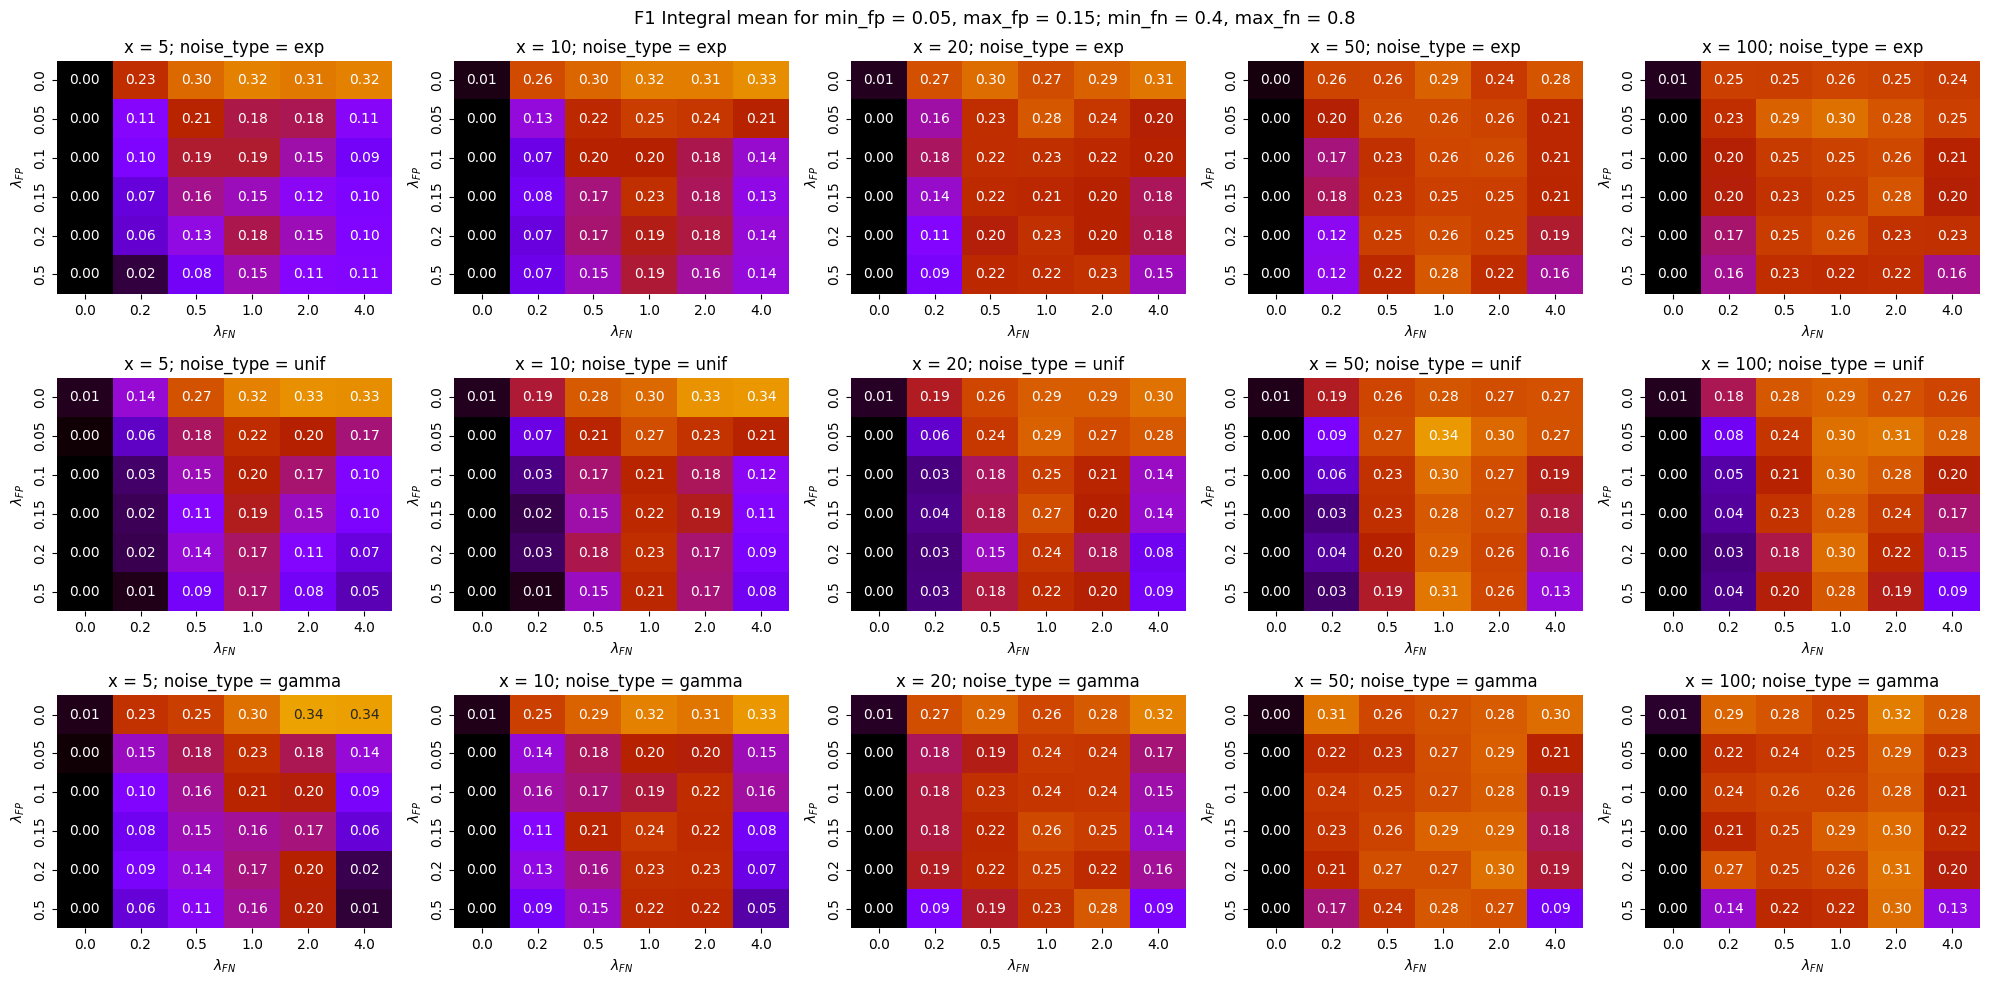

In [11]:
# Find the integrals of the F1 curves calculated for models trained on diffrent noise ranges and fisualize the result

# Specify the noise range for the test data
fn_rate_arr = [0.0, 0.2, 0.5, 1.0, 2.0, 4.0]
fp_rate_arr = [0.0, 0.05, 0.1, 0.15, 0.2, 0.5]
mean_rem_add_rates_tuples = [(add, rem) for add in fp_rate_arr for rem in fn_rate_arr]

# Specify the min and max noise ranges for the test data (the ranges for which the integrals will be calculated)
min_fn = 0.4
max_fn = 0.8

min_fp = 0.05
max_fp = 0.15

# Specify the paraters of the models trained on noise augmented data
x_range = [5, 10, 20, 50, 100]
noise_type_range = ["exp", "unif", "gamma"]

# Calculate the integrals for each trained model and visualize the result
fig, axes = plt.subplots(len(noise_type_range), len(x_range), figsize=(20,10))
for i, noise_type in enumerate(tqdm(noise_type_range, desc="Processing noise types")):
    for j, x in enumerate(x_range):
        ax = axes[i][j]
        filename_curve_dict = f"surf_area_f1_integrals_min_fp_{min_fp}_max_fp_{max_fp}_min_fn_{min_fn}_max_fn_{max_fn}_noise_type_{noise_type}_x_{x}.pkl" 
        filepath = f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename_curve_dict}"

        if os.path.exists(filepath):
            print("Loading the existing dict...")
            one_accur_dict = joblib.load(filepath)
        else:
            one_accur_dict = defaultdict(list)
            for fp_fn_tuple in mean_rem_add_rates_tuples:
                # Load the model
                filename = f"trained_models_fp_{fp_fn_tuple[0]}_fn_{fp_fn_tuple[1]}_noise_type_{noise_type}_x_{x}.pkl"
                loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
                cog_remov_add_accuracies = eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn, test_or_val = "val")
    
                # Find the FP curves integrals on range [max_fp, max_fn]
                metric = 'f1'
                fp_surface_integral = fp_fn_surface_integral(metric, min_fp, max_fp, min_fn, max_fn, cog_remov_add_accuracies)#fp_curve_areas_one_model(metric, max_fp, max_fn, cog_remov_add_accuracies)     
                one_accur_dict[fp_fn_tuple] = fp_surface_integral

            joblib.dump(one_accur_dict, filepath)
            print("Saving the dict...")

        plot_model_groups_surf_int(one_accur_dict, ax, vmin=0.0, vmax=0.4, cmap="gnuplot")
        ax.set_title(f"x = {x}; noise_type = {noise_type}")
        ax.set_xlabel(r"$\lambda_{FN}$")
        ax.set_ylabel(r"$\lambda_{FP}$")

plt.suptitle(rf"F1 Integral mean for min_fp = {min_fp}, max_fp = {max_fp}; min_fn = {min_fn}, max_fn = {max_fn}", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/f1_integral_actoss_noise.svg", format="svg", bbox_inches='tight') #<-------save as pdf    
plt.savefig(f"{OUTPUT_DIRECTORY}/plots/f1_integral_actoss_noise.pdf", format="pdf", bbox_inches='tight') #<-------save as pdf    

Processing noise types:   0%|                                                                                                                                       | 0/3 [00:00<?, ?it/s]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  33%|██████████████████████████████████████████▎                                                                                    | 1/3 [00:01<00:03,  2.00s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  67%|████████████████████████████████████████████████████████████████████████████████████▋                                          | 2/3 [00:04<00:02,  2.22s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:07<00:00,  2.49s/it]


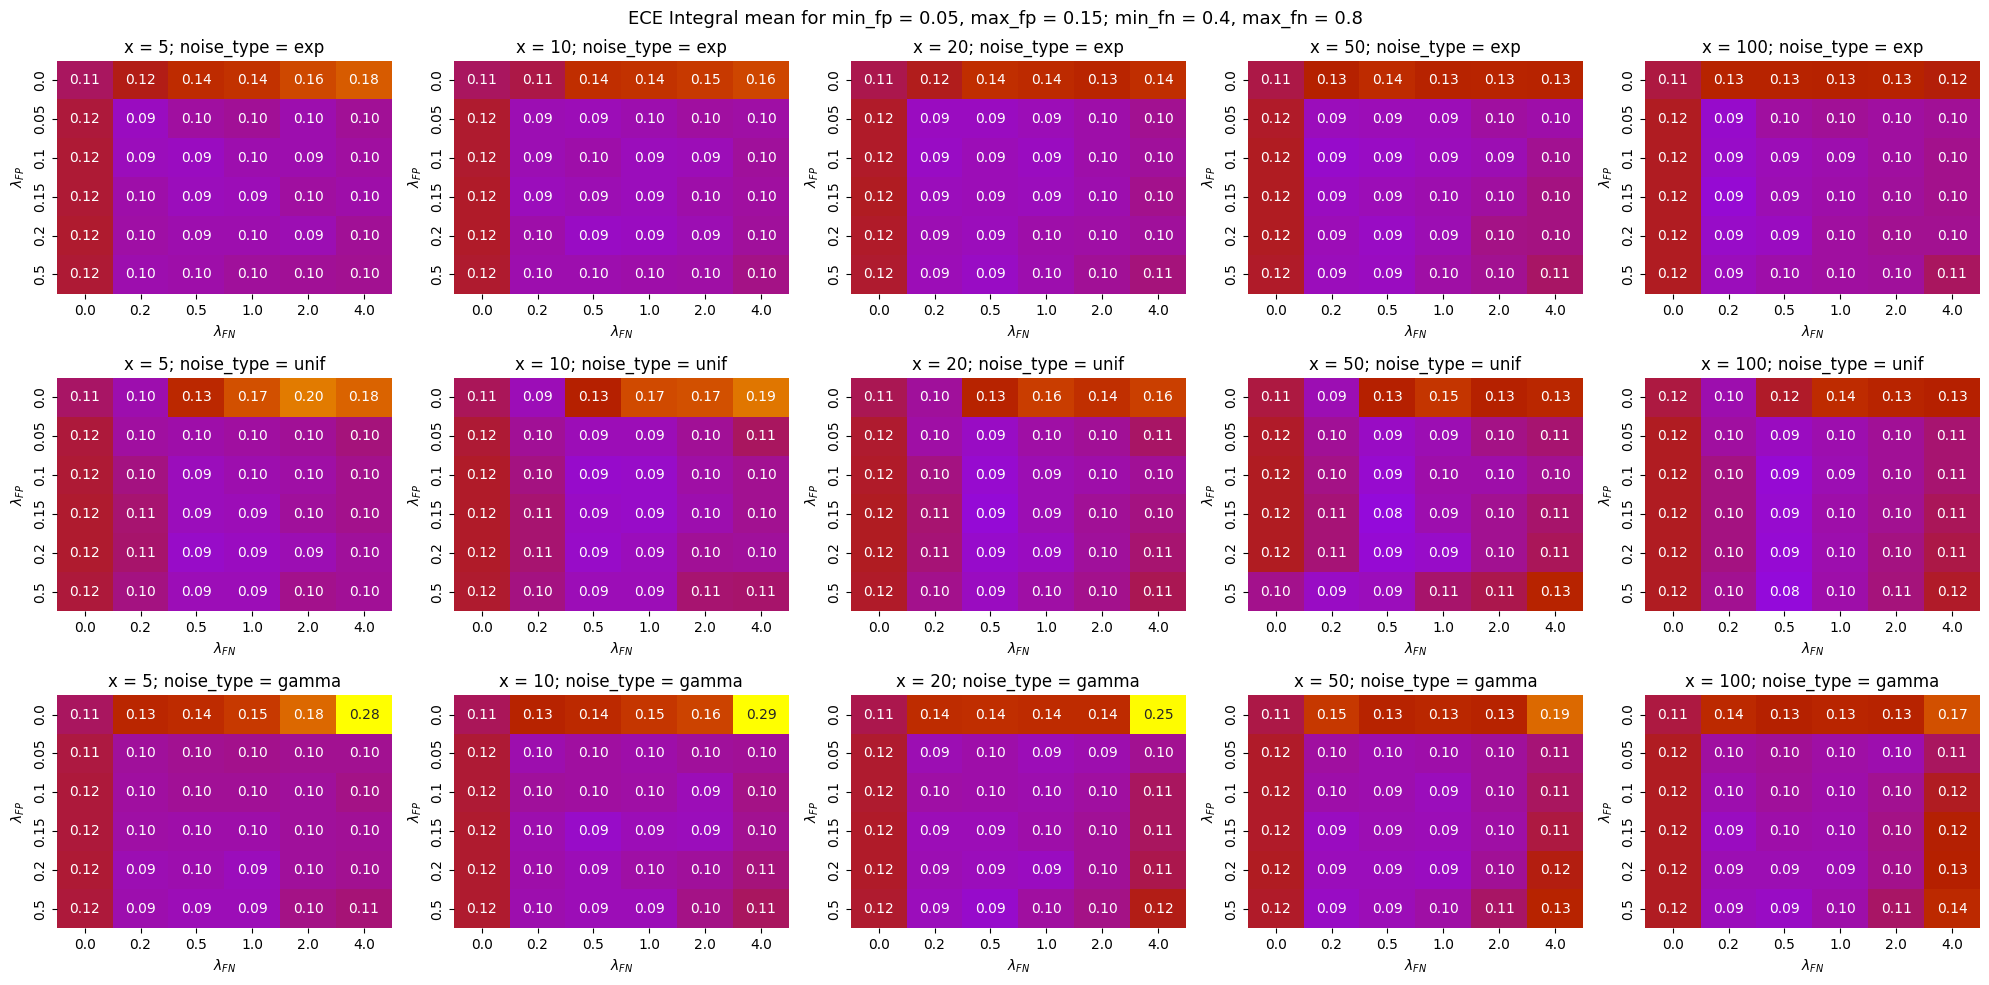

In [12]:
# Find the integrals of the ECE curves calculated for models trained on diffrent noise ranges and fisualize the result

# Specify the noise range for the test data
fn_rate_arr = [0.0, 0.2, 0.5, 1.0, 2.0, 4.0]
fp_rate_arr = [0.0, 0.05, 0.1, 0.15, 0.2, 0.5]
mean_rem_add_rates_tuples = [(add, rem) for add in fp_rate_arr for rem in fn_rate_arr]

# Specify the min and max noise ranges for the test data (the ranges for which the integrals will be calculated)
min_fn = 0.4
max_fn = 0.8

min_fp = 0.05
max_fp = 0.15

# Specify the paraters of the models trained on noise augmented data
x_range = [5, 10, 20, 50, 100]
noise_type_range = ["exp", "unif", "gamma"]

# Calculate the integrals for each trained model and visualize the result
fig, axes = plt.subplots(len(noise_type_range), len(x_range), figsize=(20,10))
for i, noise_type in enumerate(tqdm(noise_type_range, desc="Processing noise types")):
    for j, x in enumerate(x_range):
        ax = axes[i][j]
        filename_curve_dict = f"surf_area_ece_integrals_min_fp_{min_fp}_max_fp_{max_fp}_min_fn_{min_fn}_max_fn_{max_fn}_noise_type_{noise_type}_x_{x}.pkl" 
        filepath = f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename_curve_dict}"

        if os.path.exists(filepath):
            print("Loading the existing dict...")
            one_accur_dict = joblib.load(filepath)
        else:
            one_accur_dict = defaultdict(list)
            for fp_fn_tuple in mean_rem_add_rates_tuples:
                # Load the model
                filename = f"trained_models_fp_{fp_fn_tuple[0]}_fn_{fp_fn_tuple[1]}_noise_type_{noise_type}_x_{x}.pkl"
                loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
                cog_remov_add_accuracies = eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn, test_or_val = "val")
    
                # Find the FP curves integrals on range [max_fp, max_fn]
                metric = 'ece'
                fp_surface_integral = fp_fn_surface_integral(metric, min_fp, max_fp, min_fn, max_fn, cog_remov_add_accuracies)#fp_curve_areas_one_model(metric, max_fp, max_fn, cog_remov_add_accuracies)     
                one_accur_dict[fp_fn_tuple] = fp_surface_integral

            joblib.dump(one_accur_dict, filepath)
            print("Saving the dict...")

        plot_model_groups_surf_int(one_accur_dict, ax, vmin=0.0, vmax=0.25, cmap="gnuplot")
        ax.set_title(f"x = {x}; noise_type = {noise_type}")
        ax.set_xlabel(r"$\lambda_{FN}$")
        ax.set_ylabel(r"$\lambda_{FP}$")

plt.suptitle(rf"ECE Integral mean for min_fp = {min_fp}, max_fp = {max_fp}; min_fn = {min_fn}, max_fn = {max_fn}", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/ece_integral_actoss_noise.svg", format="svg", bbox_inches='tight') #<-------save as pdf    
plt.savefig(f"{OUTPUT_DIRECTORY}/plots/ece_integral_actoss_noise.pdf", format="pdf", bbox_inches='tight') #<-------save as pdf    

#### 3.2  Visualize the performance improvement for the chosen model

In [9]:
# Choose the model
x_noisy_samples = 100
fp_rate_mean = 0.1
fn_rate_mean = 1.0
noise_type = "unif"

# Load a pre-trained model
filename = f"trained_models_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x_noisy_samples}.pkl"
loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")

/home/a/an-koldaeva/local/python3.11/lib/python3.11/pickle.py:1718: UserWarning: [15:50:43] WARNING: /__w/xgboost/xgboost/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)
/flash/SzollosiU/anzhelika-koldaeva/gene-context/mlm/pytorch_3.11/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.7.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainab

In [10]:
# Calculate accuracy metrics of the chosen model across different noise ranges

from utils.utils_ancestral_predict import  eval_trained_models_on_noisy_data
cog_remov_add_accuracies = eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, test_or_val = "test")

In [12]:
allowed_fp = {0.0, 0.1, 0.2}

cog_remov_add_accuracies_filtered = {
    k: v
    for k, v in cog_remov_add_accuracies.items()
    if k[1] in allowed_fp
}

cog_remov_add_accuracies_orig_models_filtered = {
    k: v
    for k, v in cog_remov_add_accuracies_orig_models.items()
    if k[1] in allowed_fp
}

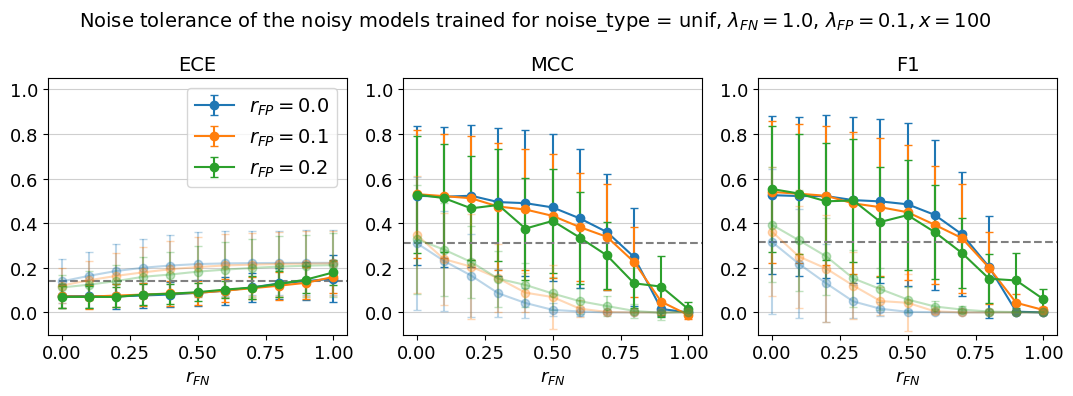

In [13]:
import matplotlib.pyplot as plt
import numpy as np

FONTSIZE=14

fig, axes = plt.subplots(1,3, figsize=(10.8, 4))

plt.subplot(1, 3, 1)
plot_one_accur_measure(axes[0], "ece", cog_remov_add_accuracies_filtered)
axes[0].legend(fontsize=FONTSIZE)
plot_one_accur_measure(axes[0], "ece", cog_remov_add_accuracies_orig_models_filtered, alpha=0.3)
axes[0].axhline(y=cog_remov_add_accuracies_orig_models_filtered[(0.0, 0.0)]['ece'][0], color='grey', linestyle='--', linewidth=1.5)
axes[0].set_ylim([-0.1,1.05])
axes[0].set_title("ECE", fontsize=FONTSIZE)
axes[0].grid(axis="y", alpha=0.6)


plt.subplot(1, 3, 2)
plot_one_accur_measure(axes[1], "mcc", cog_remov_add_accuracies_filtered)
plot_one_accur_measure(axes[1], "mcc", cog_remov_add_accuracies_orig_models_filtered, alpha=0.3)
axes[1].axhline(y=cog_remov_add_accuracies_orig_models_filtered[(0.0, 0.0)]['mcc'][0], color='grey', linestyle='--', linewidth=1.5)
axes[1].set_ylim([-0.1,1.05])
axes[1].set_title("MCC", fontsize=FONTSIZE)
axes[1].grid(axis="y", alpha=0.6)

plt.subplot(1, 3, 3)
plot_one_accur_measure(axes[2], "f1", cog_remov_add_accuracies_filtered)
plot_one_accur_measure(axes[2], "f1", cog_remov_add_accuracies_orig_models_filtered, alpha=0.3)
axes[2].axhline(y=cog_remov_add_accuracies_orig_models_filtered[(0.0, 0.0)]['f1'][0], color='grey', linestyle='--', linewidth=1.5)
axes[2].set_ylim([-0.1,1.05])
axes[2].set_title("F1", fontsize=FONTSIZE)
axes[2].grid(axis="y", alpha=0.6)

plt.suptitle(f"Noise tolerance of the noisy models trained for noise_type = {noise_type}, $\lambda_{{FN}} = {fn_rate_mean}$, $\lambda_{{FP}} = {fp_rate_mean}, x = {x_noisy_samples}$", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/noise_toler_noisy_model_FP_{fp_rate_mean}_FN_{fn_rate_mean}_x_{x_noisy_samples}.svg", format="svg", bbox_inches='tight')
plt.savefig(f"{OUTPUT_DIRECTORY}/plots/noise_toler_noisy_model_FP_{fp_rate_mean}_FN_{fn_rate_mean}_x_{x_noisy_samples}.pdf", format="pdf", bbox_inches='tight') 

In [14]:
f"{OUTPUT_DIRECTORY}/plots/noise_toler_noisy_model_FP_{fp_rate_mean}_FN_{fn_rate_mean}_x_{x_noisy_samples}.svg"

'../data_sporulation/outputs/phylum/plots/noise_toler_noisy_model_FP_0.1_FN_1.0_x_100.svg'

#### 3.2  Visualize the performance improvement for the chosen model across evo distancies

In [4]:
import pandas as pd
from Bio import Phylo

TIME_UNIT_FACTOR = 1.0   # 1000 if branch lengths are in Ga
TREE_FILE = "../ancestral_data/C65.tree"
GENOMES_INFO = "../ancestral_data/GenomesInfo.csv"
BAC_TSV = "../data_preparation/gtdb_files/bac120_metadata_r202.tsv"
ARC_TSV = "../data_preparation/gtdb_files/ar122_metadata_r202.tsv"

RANKS = ["domain", "phylum", "class", "order", "family", "genus", "species"]
RANK_IDX = {r: i for i, r in enumerate(RANKS)} 

In [5]:
LABEL_MAP = {"no": 0, "yes": 1} 

In [6]:
from utils.utils_ancestral_predict import norm

# ---- 1. Load the tree, build parent links and node ages ----
tree = Phylo.read(TREE_FILE, "newick")

parent = {}   # id(child clade) -> parent clade
age = {}      # id(clade) -> age (Ma before present)
for clade in tree.find_clades(order="postorder"):
    if clade.is_terminal():
        age[id(clade)] = 0.0
    else:
        age[id(clade)] = float(np.mean([age[id(c)] + (c.branch_length or 0.0) for c in clade.clades]))
        for c in clade.clades:
            parent[id(c)] = clade

leaf_by_name = {norm(t.name): t for t in tree.get_terminals()}
print(f"Tree has {len(leaf_by_name)} tips; root age = {age[id(tree.root)] * TIME_UNIT_FACTOR:.1f} Ma")

Tree has 1007 tips; root age = 4333.2 Ma


In [7]:
from utils.utils_ancestral_predict import acc_key

# ---- 2. Map accessions -> tree tip names (GenomesInfo.csv) ----
info = pd.read_csv(GENOMES_INFO, sep=",")
print("GenomesInfo columns:", info.columns.tolist())

# Detect which column holds tip names and which holds accessions
tip_col = next(c for c in info.columns
               if info[c].astype(str).map(norm).isin(set(leaf_by_name)).mean() > 0.5)
acc_col = next(c for c in info.columns
               if info[c].astype(str).str.contains(r"GC[AF]_\d+").mean() > 0.5)
print(f"tip column = '{tip_col}', accession column = '{acc_col}'")

acc_to_tip = dict(zip(info[acc_col].astype(str).map(acc_key),
                      info[tip_col].astype(str).map(norm)))
print(f"{len(acc_to_tip)} accessions linked to tree tips")

GenomesInfo columns: ['accession', 'ShortCode', 'r202_accession', 'checkm_completeness', 'checkm_contamination', 'quality', 'genome_size', 'gc_percentage', 'gtdb_type_designation', 'gtdb_genome_representative', 'gtdb_representative', 'ncbi_taxid', 'gtdb_taxonomy', 'phylum', 'class', 'order', 'family', 'genus', 'sp', 'taxid', 'name', 'temperature', 'morphology', 'motility', 'flagellum', 'oxytolerance', 'halotolerance', 'host-associated']
tip column = 'ShortCode', accession column = 'accession'
1007 accessions linked to tree tips


In [8]:
# ---- 3. Taxonomy for tree tips and for your genomes (GTDB) ----
gtdb = pd.concat([
    pd.read_csv(BAC_TSV, sep="\t", usecols=["accession", "gtdb_taxonomy"]),
    pd.read_csv(ARC_TSV, sep="\t", usecols=["accession", "gtdb_taxonomy"]),
])
tax_by_acc = dict(zip(gtdb["accession"].map(acc_key), gtdb["gtdb_taxonomy"].str.split(";")))

# Tree tips -> taxonomy (via their accession in GenomesInfo.csv)
taxon_to_tips = {}   # (rank, taxon) -> list of tip names
n_tips_with_tax = 0
for acc, tip in acc_to_tip.items():
    tax = tax_by_acc.get(acc)
    if tax is None or tip not in leaf_by_name:
        continue
    n_tips_with_tax += 1
    for rank, taxon in zip(RANKS, tax):
        if taxon.endswith("__"):        # empty rank, e.g. 'g__'
            continue
        taxon_to_tips.setdefault((rank, taxon), []).append(tip)
print(f"{n_tips_with_tax}/{len(leaf_by_name)} tree tips have GTDB taxonomy")


# ---- 4. Place a genome on the tree by its lowest rank present in the tree ----
# _clade_cache = {}



997/1007 tree tips have GTDB taxonomy


In [9]:
from utils.utils_ancestral_predict import read_acc
# All accessions in the dataset (every genome appears in train, val or test of any split)
_base = f"../{DATA_DIRECTORY}/input_data_train_val_test/class"
ALL_ACC = sorted(set(
    read_acc(f"{_base}/train_annot_class_split_0")
    + read_acc(f"{_base}/val_annot_class_split_0")
    + read_acc(f"{_base}/test_annot_class_split_0")
))
phylum_of = {a: tax_by_acc[acc_key(a)][1] for a in ALL_ACC if acc_key(a) in tax_by_acc}

In [10]:
import joblib
from tqdm import tqdm
from xgboost import XGBClassifier
from sklearn.pipeline import make_pipeline
from utils.utils_ancestral_predict import eval_trained_models_on_noisy_data, plot_one_accur_measure

def train_and_evaluate_orig_models(all_splits_dict):
    # Train and save models for each data split
    trained_models = {}
    for split_id in all_splits_dict.keys():#tqdm(all_splits_dict.keys(), desc="Training splits"):
        X_val_train = all_splits_dict[split_id]["X_train"]
        y_label_train = all_splits_dict[split_id]["y_train"]
    
        pipe = make_pipeline(
            make_pipeline(XGBClassifier(n_jobs=THREADS if DEVICE == "cpu" else None, tree_method="gpu_hist" if DEVICE == "cpu" else "hist"))
        )
        pipe.fit(X_val_train.cpu(), y_label_train.cpu())
        trained_models[split_id] = pipe
    cog_remov_add_accuracies_orig_models = eval_trained_models_on_noisy_data(all_splits_dict, trained_models, hard_fn_flag = True, return_raw = True) 
    
    return cog_remov_add_accuracies_orig_models

In [11]:
from utils.utils_ancestral_predict import read_splits

from collections import defaultdict

NUM_SPLITS_TO_READ = 26

tax_levels = ["random", "family", "order", "class", "phylum"]

mcc_tax_levels = defaultdict()
for tax_level in tqdm(tax_levels, desc="Tax levels"):
    all_splits_dict = read_splits(tax_level, DATA_DIRECTORY, NUM_SPLITS_TO_READ, LABEL_MAP, ALL_ACC, phylum_of)
    cog_remov_add_accuracies_orig_models = train_and_evaluate_orig_models(all_splits_dict)
    mcc_tax_levels[tax_level] = cog_remov_add_accuracies_orig_models#[(fn, fp)]['mcc']

Tax levels:  60%|█████████████████████████████████████████████████████████████████████████████████████████████████▊                                                                 | 3/5 [11:01<07:32, 226.44s/it]

  Missing or empty validation data for split 17; using empty validation fields.


Tax levels: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [15:11<00:00, 182.37s/it]


In [12]:
from utils.utils_ancestral_predict import  eval_trained_models_on_noisy_data

# Choose a model
TRAINED_MOD_DIR = "trained_models_train_val_test"
x_noisy_samples = 100
fp_rate_mean = 0.1
fn_rate_mean = 1.0
noise_type = "unif"
filename = f"trained_models_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x_noisy_samples}.pkl"

mcc_tax_levels_noise_rob_models = defaultdict()
for tax_level in tqdm(tax_levels, desc="Tax levels"):
    all_splits_dict = read_splits(tax_level, DATA_DIRECTORY, NUM_SPLITS_TO_READ, LABEL_MAP, ALL_ACC, phylum_of)
    OUTPUT_DIRECTORY = f"../{DATA_DIRECTORY}/outputs/{tax_level}"
    loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
    cog_remov_add_accuracies = eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, test_or_val = "test", return_raw = True)
    mcc_tax_levels_noise_rob_models[tax_level] = cog_remov_add_accuracies

Tax levels:  60%|██████████████████████████████████████████████████████████████████████████████████████████████████▍                                                                 | 3/5 [04:26<02:49, 84.89s/it]

  Missing or empty validation data for split 17; using empty validation fields.


Tax levels:  80%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏                                | 4/5 [05:54<01:26, 86.23s/it]/home/a/an-koldaeva/local/python3.11/lib/python3.11/pickle.py:1718: UserWarning: [16:00:01] WARNING: /__w/xgboost/xgboost/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)
/flash/SzollosiU/anzhelika-koldaeva/gene-context/mlm/pytorch_3.11/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1

In [13]:
from tqdm import tqdm
from utils.utils_ancestral_predict import  nearest_train_times

per_split_time = {}   # level -> {split_id: median distance in Ma}
per_split_n = {}
#for lvl in LEVELS:
for tax_level in tqdm(tax_levels, desc="Tax levels"):     #tax_levels
    splits = read_splits(tax_level, DATA_DIRECTORY, NUM_SPLITS_TO_READ, LABEL_MAP, ALL_ACC, phylum_of)
    per_split_time[tax_level] = {}
    per_split_n[tax_level] = {}
    for split_id, d in splits.items():
        times, missing = nearest_train_times(d["acc_train"], d["acc_test"], RANK_IDX, RANKS, tax_by_acc, taxon_to_tips, acc_key, tree, leaf_by_name, age, parent, coarsest_rank="genus")
        per_split_time[tax_level][split_id] = np.min(times) #or median
        per_split_n[tax_level][split_id] = (len(times), missing, len(d["acc_test"]))
    vals = list(per_split_time[tax_level].values())
    print(f"{tax_level:>7}: metric over {len(vals)} splits = {np.median(vals):6.0f} Ma "
          f"(range {np.min(vals):.0f} to {np.max(vals):.0f})")

#pd.DataFrame(per_split_time).to_csv("divergence_time_per_split.csv")

Tax levels:  20%|████████████████████████████████▊                                                                                                                                   | 1/5 [01:33<06:13, 93.30s/it]

 random: metric over 26 splits =      0 Ma (range 0 to 0)


Tax levels:  40%|█████████████████████████████████████████████████████████████████▌                                                                                                  | 2/5 [02:48<04:08, 82.87s/it]

 family: metric over 26 splits =   1600 Ma (range 1240 to 2452)


Tax levels:  60%|██████████████████████████████████████████████████████████████████████████████████████████████████▍                                                                 | 3/5 [04:05<02:39, 79.84s/it]

  order: metric over 26 splits =   1730 Ma (range 1600 to 2730)
  Missing or empty validation data for split 17; using empty validation fields.


Tax levels:  80%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏                                | 4/5 [05:24<01:19, 79.47s/it]

  class: metric over 26 splits =   3587 Ma (range 3286 to 5421)


Tax levels: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [06:12<00:00, 74.48s/it]

 phylum: metric over 26 splits =   5513 Ma (range 4780 to 7622)


In [16]:
per_split_time_mean_stds = defaultdict()

for taxa in per_split_time.keys():
    mn = np.mean(list(per_split_time[taxa].values()))
    std = np.std(list(per_split_time[taxa].values()))
    per_split_time_mean_stds[taxa] = (mn, std)

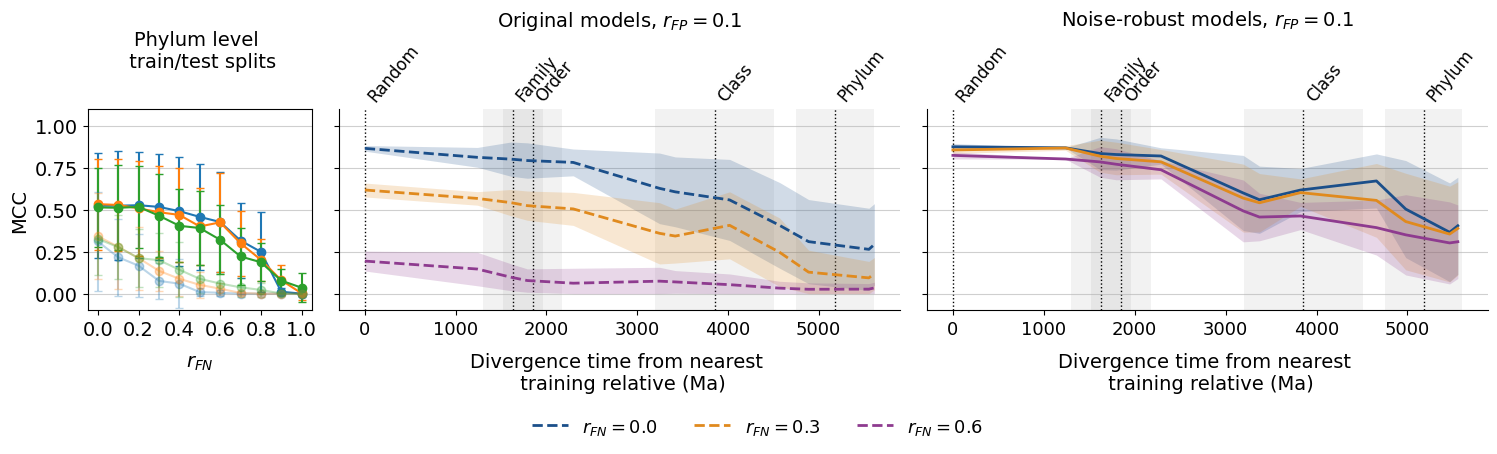

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from utils.utils_ancestral_predict import rolling_mean_std_curve

tax_levels = ["random", "family", "order", "class", "phylum"]
colors = ["#1B4F8A", "#E08A1E", "#8E3B8F"]  # ["tab:blue", "tab:orange", "tab:green"]

fp = 0.1
fn_range = [0.0, 0.3, 0.6]

FONTSIZE = 14

fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.5), sharey=True,
    gridspec_kw={"width_ratios": [0.4, 1, 1]}
)
# ---------------------------------------------------------------
# Corridors (mean ± std of divergence time per taxonomic level),
# drawn ONCE, outside the fn loop
# ---------------------------------------------------------------
tick_pos, tick_lab = [], []
for tax_level in tax_levels:
    t = np.asarray(list(per_split_time[tax_level].values()), dtype=float)
    t = t[t <= 6000]
    mu, sd = t.mean(), t.std()

    for ax in [axes[1], axes[2]]:
        ax.axvspan(mu - sd, mu + sd, color="grey",
                   alpha=0.1, linewidth=0, zorder=0)
        ax.axvline(mu, color="black", linestyle=":",
                   linewidth=1, zorder=1)

    tick_pos.append(mu)
    tick_lab.append(tax_level.capitalize())

# ---------------------------------------------------------------
# Curves
# ---------------------------------------------------------------
for i, fn in enumerate(fn_range):
    all_points_x = []
    all_points_y = []
    all_points_x_noise_rob_mod = []
    all_points_y_noise_rob_mod = []

    for tax_level in tax_levels:
        # orig model
        all_points_x += list(per_split_time[tax_level].values())
        all_points_y += list(mcc_tax_levels[tax_level][(fn, fp)]['mcc'])

        # noise-robust model
        n = len(mcc_tax_levels_noise_rob_models[tax_level][(fn, fp)]['mcc'])
        all_points_x_noise_rob_mod += list(per_split_time[tax_level].values())[:n]
        all_points_y_noise_rob_mod += list(mcc_tax_levels_noise_rob_models[tax_level][(fn, fp)]['mcc'])

    # orig model filtered
    x_arr = np.asarray(all_points_x, dtype=float)
    y_arr = np.asarray(all_points_y, dtype=float)
    mask = x_arr <= 6000
    all_points_x = x_arr[mask]
    all_points_y = y_arr[mask]

    # noise-robust model filtered
    x_arr = np.asarray(all_points_x_noise_rob_mod, dtype=float)
    y_arr = np.asarray(all_points_y_noise_rob_mod, dtype=float)
    mask = x_arr <= 6000
    all_points_x_noise_rob_mod = x_arr[mask]
    all_points_y_noise_rob_mod = y_arr[mask]

    x_mean, y_mean, y_std = rolling_mean_std_curve(
        all_points_x, all_points_y, window=1000
    )
    x_mean_nr, y_mean_nr, y_std_nr = rolling_mean_std_curve(
        all_points_x_noise_rob_mod, all_points_y_noise_rob_mod, window=1000
    )

    label = fr"$r_{{FN}} = {fn}$"

    # Left: original models
    axes[1].fill_between(x_mean,
                         np.clip(y_mean - y_std, 0, 1),
                         np.clip(y_mean + y_std, 0, 1),
                         color=colors[i], alpha=0.2, linewidth=0, zorder=2)
    axes[1].plot(x_mean, y_mean, c=colors[i], linestyle="--",
                 linewidth=2, label=label, zorder=3)

    # Right: noise-robust models
    axes[2].fill_between(x_mean_nr,
                         np.clip(y_mean_nr - y_std_nr, 0, 1),
                         np.clip(y_mean_nr + y_std_nr, 0, 1),
                         color=colors[i], alpha=0.2, linewidth=0, zorder=2)
    axes[2].plot(x_mean_nr, y_mean_nr, c=colors[i], linestyle="-",
                 linewidth=2, label=label, zorder=3)


#plt.subplot(1, 3, 2)
cog_remov_add_accuracies_mn_std = {}
cog_remov_add_accuracies_orig_models_mn_std = {}
for rates in cog_remov_add_accuracies.keys():
    cog_remov_add_accuracies_mn_std[rates] = {}
    cog_remov_add_accuracies_orig_models_mn_std[rates] = {}
    for metric in cog_remov_add_accuracies[rates].keys():
        cog_remov_add_accuracies_mn_std[rates][metric] = (np.mean(cog_remov_add_accuracies[rates][metric] ), np.std(cog_remov_add_accuracies[rates][metric] ))
        cog_remov_add_accuracies_orig_models_mn_std[rates][metric] = (np.mean(cog_remov_add_accuracies_orig_models[rates][metric] ), np.std(cog_remov_add_accuracies_orig_models[rates][metric] ))

allowed_fp = {0.0, 0.1, 0.2}

cog_remov_add_accuracies_mn_std_filtered = {
    k: v
    for k, v in cog_remov_add_accuracies_mn_std.items()
    if k[1] in allowed_fp
}

cog_remov_add_accuracies_orig_models_mn_std_filtered = {
    k: v
    for k, v in cog_remov_add_accuracies_orig_models_mn_std.items()
    if k[1] in allowed_fp
}

plot_one_accur_measure(axes[0], "mcc", cog_remov_add_accuracies_mn_std_filtered)
plot_one_accur_measure(axes[0], "mcc", cog_remov_add_accuracies_orig_models_mn_std_filtered, alpha=0.3, fontsize = FONTSIZE)
# axes[2].axhline(y=cog_remov_add_accuracies_orig_models[(0.0, 0.0)]['mcc'][0], color='grey', linestyle='--', linewidth=1.5)
# axes[2].set_ylim([-0.1,1.05])
# axes[2].set_title("MCC", fontsize=FONTSIZE)


# ---------------------------------------------------------------
# Axes styling
# ---------------------------------------------------------------
for ax in [axes[1], axes[2]]:
    # second x-axis layer with taxonomic level names
    sec = ax.secondary_xaxis("top")
    sec.set_xticks(tick_pos)
    sec.set_xticklabels(tick_lab, rotation=50, ha="left")
    sec.tick_params(labelsize=12, length=0)
    sec.spines["top"].set_visible(False)

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.6)
    ax.tick_params(labelsize=13)
    ax.set_ylim([-0.1, 1.1])
    ax.set_xlabel("Divergence time from nearest \n training relative (Ma)", fontsize=14, labelpad=10)

axes[1].set_title(fr"Original models, $r_{{FP}} = {fp}$", fontsize=14, pad=10)
axes[2].set_title(fr"Noise-robust models, $r_{{FP}} = {fp}$", fontsize=14, pad=10)
axes[0].set_ylabel("MCC", fontsize=14)

axes[0].grid(axis="y", alpha=0.6)
axes[0].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
axes[0].set_title("Phylum level \n train/test splits", fontsize=14, pad=30)
axes[0].set_xlabel(r"$r_{FN}$", fontsize=14, labelpad=10)

# one shared legend instead of one per panel
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3,
           frameon=False, fontsize=13, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_in_evo_dist_fp_{fp}.svg",
    format="svg",
    bbox_inches="tight",
)

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_in_evo_dist_fp_{fp}.pdf",
    format="pdf",
    bbox_inches="tight",
)

plt.show()

In [20]:
f"{OUTPUT_DIRECTORY}/plots/noise_in_evo_dist_fp_{fp}.pdf"

'../data_sporulation/outputs/phylum/plots/noise_in_evo_dist_fp_0.0.pdf'

### 4.  Ancestral phenotype prediction

#### 4.1  ML predictions

In [40]:
# Read the annotated count table and get the list of COGs from there
sporul_cogs = pd.read_csv("../data_sporulation/sporulation_kegg.csv", sep=",")
X_column_names = sporul_cogs.columns[sporul_cogs.columns.str.startswith("COG")].tolist()

In [41]:
# Read the GTDB tables for the genome taxonomy
import polars as pl

BAC_TSV = '../data_preparation/gtdb_files/bac120_metadata_r202.tsv'
ARC_TSV = '../data_preparation/gtdb_files/ar122_metadata_r202.tsv'

tax_level = "phylum"
tax_levels = {"domain": 0, "phylum": 1, "class": 2, "order": 3, "family": 4}

gtdb_df = pl.concat([pl.read_csv(BAC_TSV, separator="\t"),
    pl.read_csv(ARC_TSV, separator="\t")])
gtdb_df = gtdb_df[['accession', "gtdb_taxonomy"]]
for key in tax_levels.keys():
    tax_level = tax_levels[key]
    gtdb_df = gtdb_df.with_columns(pl.col("gtdb_taxonomy").str.split(';').list.get(tax_levels[key]).alias(key))
gtdb_df = gtdb_df.drop("gtdb_taxonomy")
#gtdb_df = gtdb_df[['accession', tax_level]]
gtdb_df = gtdb_df.to_pandas()

In [42]:
# Get the species tree leaf node names
leaves_acc_names = pd.read_csv("../ancestral_data/GenomesInfo.csv", sep=",")
columns_to_keep = ['accession', 'ShortCode']
leaves_acc_names = leaves_acc_names[columns_to_keep]
leaves_acc_names

,accession,ShortCode
0,GB_GCA_003599535.1,AABM5X1
1,GB_GCA_005223185.1,AABM5X2
2,GB_GCA_002127415.1,AABM5X3
3,GB_GCA_003598085.1,Abys1
4,GB_GCA_003223555.1,Acid1
...,...,...
1002,GB_GCA_001775395.1,Zixi1
1003,GB_GCA_002791595.1,Zixi2
1004,GB_GCA_003105265.1,Zixi3
1005,GB_GCA_002838945.1,Zixi4


In [43]:
leave_nodes_with_taxonomy = pd.merge(leaves_acc_names, gtdb_df, on="accession", how="inner")
leave_nodes_with_taxonomy

,accession,ShortCode,domain,phylum,class,order,family
0,GB_GCA_003599535.1,AABM5X1,d__Bacteria,p__AABM5-125-24,c__B3-LCP,o__B3-LCP,f__B3-LCP
1,GB_GCA_005223185.1,AABM5X2,d__Bacteria,p__AABM5-125-24,c__B3-LCP,o__B3-LCP,f__B3-LCP
2,GB_GCA_002127415.1,AABM5X3,d__Bacteria,p__AABM5-125-24,c__AABM5-125-24,o__AABM5-125-24,f__AABM5-125-24
3,GB_GCA_003598085.1,Abys1,d__Bacteria,p__Abyssubacteria,c__SURF-5,o__SURF-5,f__SURF-5
4,GB_GCA_003223555.1,Acid1,d__Bacteria,p__Acidobacteriota,c__Vicinamibacteria,o__Fen-336,f__Fen-336
...,...,...,...,...,...,...,...
992,GB_GCA_001775395.1,Zixi1,d__Bacteria,p__Zixibacteria,c__MSB-5A5,o__UBA10806,f__UBA10806
993,GB_GCA_002791595.1,Zixi2,d__Bacteria,p__Zixibacteria,c__MSB-5A5,o__UM-FILTER-46-8,f__UM-FILTER-46-8
994,GB_GCA_003105265.1,Zixi3,d__Bacteria,p__Zixibacteria,c__MSB-5A5,o__GN15,f__FEB-12
995,GB_GCA_002838945.1,Zixi4,d__Bacteria,p__Zixibacteria,c__MSB-5A5,o__GN15,f__PGXB01


In [44]:
# Read the tree file and pivot it into a COG count table
df = pd.read_csv('../ancestral_data/TableAncestralRoot1_aggregated_byCOG.tsv', sep='\t', dtype={'column_name': str})
df = df.T

df.columns = df.loc['COG']
df = df.drop(index='COG')
df.columns.name = None

pivot_df = df.apply(pd.to_numeric)
pivot_df.index = pivot_df.index.str.replace(r'\(\d+\)$', '', regex=True)

node_names = pivot_df.index.tolist()
pivot_df

,COG0001,COG0002,COG0003,COG0004,COG0005,COG0006,COG0007,COG0008,COG0010,COG0012,...,COG5611,COG5615,COG5621,COG5625,COG5632,COG5640,COG5643,COG5650,COG5652,COG5663
AABM5X1,1.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
AABM5X2,1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
AABM5X3,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
Abys1,1.00,1.00,1.00,1.00,1.00,0.00,0.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
Acid1,1.00,1.00,1.00,1.00,1.00,1.00,0.00,1.00,0.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008,0.55,0.58,0.76,0.37,1.00,0.01,0.12,1.00,1.00,0.23,...,0.01,0.0,0.01,0.0,0.00,0.0,0.0,0.0,0.01,0.0
2009,0.26,0.38,0.09,0.31,0.91,0.00,0.24,0.68,0.08,1.00,...,0.02,0.0,0.00,0.0,0.02,0.0,0.0,0.0,0.09,0.0
2010,0.24,0.51,0.91,0.13,0.70,0.00,0.06,1.00,0.68,0.15,...,0.01,0.0,0.03,0.0,0.00,0.0,0.0,0.0,0.01,0.0
2011,0.08,0.07,0.14,0.08,0.29,0.00,0.05,0.88,0.23,0.13,...,0.00,0.0,0.01,0.0,0.00,0.0,0.0,0.0,0.00,0.0


In [54]:
# # Optionally: threshold the COG count values to convert them to 0/1s
# threshold = 0.01
# pivot_df = pivot_df.applymap(lambda x: 0 if x <= threshold else max(x, 1))
# pivot_df

In [45]:
# Find COGs that are in the intersection between the COG set from the species tree and the COGs from the annotated data

cogs_from_mastertable = list(pivot_df.columns)
cogs_intersect = list(set(cogs_from_mastertable) & set(X_column_names))
cogs_intersect = sorted(cogs_intersect, key=lambda x: int(x[3:]))

# Apply the intersection COGs to the species tree count table
tree_nodes_data = pivot_df[cogs_intersect]
tree_nodes_data

,COG0001,COG0002,COG0003,COG0004,COG0005,COG0006,COG0007,COG0008,COG0010,COG0012,...,COG5611,COG5615,COG5621,COG5625,COG5632,COG5640,COG5643,COG5650,COG5652,COG5663
AABM5X1,1.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
AABM5X2,1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
AABM5X3,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
Abys1,1.00,1.00,1.00,1.00,1.00,0.00,0.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
Acid1,1.00,1.00,1.00,1.00,1.00,1.00,0.00,1.00,0.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008,0.55,0.58,0.76,0.37,1.00,0.01,0.12,1.00,1.00,0.23,...,0.01,0.0,0.01,0.0,0.00,0.0,0.0,0.0,0.01,0.0
2009,0.26,0.38,0.09,0.31,0.91,0.00,0.24,0.68,0.08,1.00,...,0.02,0.0,0.00,0.0,0.02,0.0,0.0,0.0,0.09,0.0
2010,0.24,0.51,0.91,0.13,0.70,0.00,0.06,1.00,0.68,0.15,...,0.01,0.0,0.03,0.0,0.00,0.0,0.0,0.0,0.01,0.0
2011,0.08,0.07,0.14,0.08,0.29,0.00,0.05,0.88,0.23,0.13,...,0.00,0.0,0.01,0.0,0.00,0.0,0.0,0.0,0.00,0.0


In [46]:
# Prepare model train data
sporul_cogs = pd.read_csv("../data_sporulation/sporulation_kegg.csv", sep=",")
sporul_annot = pd.read_csv("../data_sporulation/sporulation_annot.csv", sep=",")
merged_tab  = pd.merge(sporul_cogs, sporul_annot, on="accession", how="inner")  
merged_tab

,accession,COG0001,COG0002,COG0003,COG0004,COG0005,COG0006,COG0007,COG0008,COG0009,...,COG5657,COG5658,COG5659,COG5660,COG5661,COG5662,COG5663,COG5664,COG5665,sporulation
0,GB_GCA_000023725.1,1,1,0,0,0,1,0,2,2,...,0,0,0,0,0,0,0,0,0,no
1,GB_GCA_000026125.1,2,2,0,2,0,1,2,3,2,...,0,0,0,0,0,1,0,0,0,no
2,GB_GCA_000043285.1,0,0,0,0,0,0,1,2,1,...,0,0,0,0,0,0,0,0,0,no
3,GB_GCA_000063505.1,1,1,0,1,1,1,1,2,1,...,0,0,0,0,0,0,0,0,0,no
4,GB_GCA_000063525.1,1,1,0,1,1,1,1,2,1,...,0,0,0,0,0,0,0,0,0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4636,RS_GCF_946478525.1,1,1,0,1,0,1,0,3,2,...,0,0,0,0,0,0,0,0,0,no
4637,RS_GCF_949281285.1,0,1,0,1,1,1,1,3,1,...,0,0,2,0,0,0,0,0,0,no
4638,RS_GCF_951793255.1,1,1,0,1,1,1,1,3,1,...,0,0,0,0,0,0,0,0,0,no
4639,RS_GCF_958453765.1,1,1,0,1,1,2,1,3,1,...,0,0,0,0,0,0,0,0,0,no


In [47]:
# Prepare phenotype annotation vector

y_label_train = torch.tensor(merged_tab["sporulation"].map({"yes": 1, "no": 0}).to_numpy(), dtype=torch.long)

numeric_df = merged_tab.iloc[:, 1:-1]
numeric_values = torch.tensor(numeric_df.values, dtype=torch.float32)
numeric_values = (numeric_values> 0).int()  

X_column_names = merged_tab.columns.tolist()[1:-1]
name_to_idx = {name: i for i, name in enumerate(X_column_names)}

# Keep only those in cogs_intersect AND present in X_column_names
keep_indices = [name_to_idx[cog] for cog in cogs_intersect if cog in name_to_idx]

# Filter tensor and column names
X_val_train_filtered = numeric_values[:, keep_indices]
X_column_names_filtered = [X_column_names[i] for i in keep_indices]
X_val_train_filtered.shape

torch.Size([4641, 2848])

In [48]:
# Initialize XGBoost for training

from xgboost import XGBClassifier

tree_method = "hist"

def make_xgb():
    return XGBClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.7,
        colsample_bytree=0.7,
        reg_alpha=1.0,
        reg_lambda=2.0,
        min_child_weight=5,
        tree_method=tree_method,
        n_jobs=-1
    )  

In [49]:
from utils.utils_ancestral_predict import augment_data_with_noise

# Augment X train with the noise 
x = 100
fp_rate_mean = 0.05
fn_rate_mean = 1.0
noise_type = "exp"

X_augmented, y_augmented = augment_data_with_noise(X_val_train_filtered, y_label_train, x, fp_rate_mean, fn_rate_mean, noise_type=noise_type)#, filename=None)
X_augmented.shape

torch.Size([468741, 2848])

In [50]:
from sklearn.pipeline import make_pipeline

# Train a model on noise augmented data
pipe = make_pipeline(make_xgb())
pipe.fit(X_augmented.cpu(), y_augmented.cpu());

In [51]:
# Convert tree genomes to a tensor
numeric_df = tree_nodes_data.select_dtypes(include=["number"])
ancestral_nodes_tensor = torch.tensor(numeric_df.to_numpy())

# Apply the trained model to the tree genomes
y_pred_ancestr_nodes = pipe.predict(ancestral_nodes_tensor.cpu())

# Predict the probabilities of each class and find the maximum probability
y_proba_ancestr_nodes = pipe.predict_proba(ancestral_nodes_tensor.cpu())
max_proba = [max(x) for x in y_proba_ancestr_nodes]

In [52]:
# Generate a table with all genome names from the species tree and the model predictions

# Count for the correctly predicted extant genomes (the ones whose true annotations we know)
correct = 0
total = 0

# Arrays for storing the values for each tree node 
annot_vs_pred_label = []
oxytolerance = []

tree_node_names_list = tree_nodes_data.index.tolist()
merged_df = pd.merge(sporul_annot, leaves_acc_names, on="accession", how="left")

# Iterate over all nodes in the species tree 
for idx, node in enumerate(tree_node_names_list):
    if node in list(merged_df['ShortCode']):
        oxytol = merged_df.loc[merged_df["ShortCode"] == node, "sporulation"]
        oxytolerance.append(oxytol.iloc[0])
        annot_vs_pred_label.append("annot")

        # Count the number or correctly predicted extant genomes
        if (oxytol.iloc[0] == "yes" and y_pred_ancestr_nodes[idx] == 1) or (oxytol.iloc[0] == "no" and y_pred_ancestr_nodes[idx] == 0):
            correct += 1
        total +=1    
        
    else:
        annot_vs_pred_label.append("predict")
        oxytolerance.append("yes" if y_pred_ancestr_nodes[idx] == 1 else "no")  #.map({'no': 0, 'yes': 1})

# Generate the final table
df_pred = pd.DataFrame({
    'NodeName': tree_node_names_list,
    'sporulation': oxytolerance,
    'annot_or_predict':annot_vs_pred_label,
    'max_proba': max_proba,
    "proba_and_uncert": y_proba_ancestr_nodes[:, 1]
})

print(f"Correct predict = {correct} of {total}; which is {correct/total}")
df_pred

Correct predict = 49 of 52; which is 0.9423076923076923


,NodeName,sporulation,annot_or_predict,max_proba,proba_and_uncert
0,AABM5X1,no,predict,0.715864,0.284136
1,AABM5X2,no,predict,0.840523,0.159477
2,AABM5X3,no,predict,0.852119,0.147881
3,Abys1,no,predict,0.883169,0.116831
4,Acid1,no,predict,0.919677,0.080323
...,...,...,...,...,...
2008,2008,no,predict,0.898423,0.101577
2009,2009,no,predict,0.852702,0.147298
2010,2010,no,predict,0.884980,0.115020
2011,2011,no,predict,0.865605,0.134395


In [53]:
# Print the prediction results for the root node
print(df_pred.loc[df_pred["NodeName"] == '2012', "sporulation"].iloc[0])
print(df_pred.loc[df_pred["NodeName"] == '2012', "max_proba"].iloc[0])

no
0.86838126


#### 4.2.  Wagner predictions

In [55]:
from Bio import Phylo

# Read the already existing tree file that we annotate with the model predictions below 
tree = Phylo.read("../ancestral_data/C65.tree", "newick")

In [56]:
merged_tab

,accession,COG0001,COG0002,COG0003,COG0004,COG0005,COG0006,COG0007,COG0008,COG0009,...,COG5657,COG5658,COG5659,COG5660,COG5661,COG5662,COG5663,COG5664,COG5665,sporulation
0,GB_GCA_000023725.1,1,1,0,0,0,1,0,2,2,...,0,0,0,0,0,0,0,0,0,no
1,GB_GCA_000026125.1,2,2,0,2,0,1,2,3,2,...,0,0,0,0,0,1,0,0,0,no
2,GB_GCA_000043285.1,0,0,0,0,0,0,1,2,1,...,0,0,0,0,0,0,0,0,0,no
3,GB_GCA_000063505.1,1,1,0,1,1,1,1,2,1,...,0,0,0,0,0,0,0,0,0,no
4,GB_GCA_000063525.1,1,1,0,1,1,1,1,2,1,...,0,0,0,0,0,0,0,0,0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4636,RS_GCF_946478525.1,1,1,0,1,0,1,0,3,2,...,0,0,0,0,0,0,0,0,0,no
4637,RS_GCF_949281285.1,0,1,0,1,1,1,1,3,1,...,0,0,2,0,0,0,0,0,0,no
4638,RS_GCF_951793255.1,1,1,0,1,1,1,1,3,1,...,0,0,0,0,0,0,0,0,0,no
4639,RS_GCF_958453765.1,1,1,0,1,1,2,1,3,1,...,0,0,0,0,0,0,0,0,0,no


In [57]:
phenotype_col = "sporulation"

# Map phenotype names to states
phenotype_map = {
    "no": 0,
    "yes": 1
}

# Create accession -> phenotype dictionary
phenotype_dict = (
    merged_tab
    .set_index("accession")[phenotype_col]
    .map(phenotype_map)
    .dropna()
    .to_dict()
)

In [58]:
# accession -> tree leaf name
accession_to_leaf = (
    leaves_acc_names
    .set_index("accession")["ShortCode"]
    .to_dict()
)

leaf_phenotype_dict = {
    accession_to_leaf[accession]: phenotype
    for accession, phenotype in phenotype_dict.items()
    if accession in accession_to_leaf
}

In [59]:
tree_leaves = {leaf.name for leaf in tree.get_terminals()}

matched = set(leaf_phenotype_dict) & tree_leaves
not_in_tree = set(leaf_phenotype_dict) - tree_leaves

print("Phenotype annotations:", len(phenotype_dict))
print("Mapped to tree names:", len(leaf_phenotype_dict))
print("Found in tree:", len(matched))
print("Not found in tree:", len(not_in_tree))

print("Examples not found:", list(not_in_tree)[:10])

Phenotype annotations: 4641
Mapped to tree names: 52
Found in tree: 52
Not found in tree: 0
Examples not found: []


In [60]:
import copy

pruned_tree = copy.deepcopy(tree)

for leaf in pruned_tree.get_terminals():
    if leaf.name not in leaf_phenotype_dict:
        pruned_tree.prune(leaf)

print("Original leaves:", len(tree.get_terminals()))
print("Pruned leaves:", len(pruned_tree.get_terminals()))

Original leaves: 1007
Pruned leaves: 52


In [61]:
all_nodes = pruned_tree.find_clades()

In [62]:
from utils.utils_ancestral_predict import wagner_reconstruction

state_labels = {
    0: "no",
    1: "yes"
}

(
    node_annotations,
    node_confidence,
    node_probabilities,
    scores,
    parsimony_score
) = wagner_reconstruction(
    pruned_tree,
    leaf_phenotype_dict,
    state_labels=state_labels
)

parsimony_score

9.0

In [63]:
def get_node_id(node):
    if node.name is not None:
        return str(node.name)
    elif node.confidence is not None:
        return str(node.confidence)
    else:
        return None

In [64]:
print("annotations:", len(node_annotations))
print("confidence:", len(node_confidence))
print("probabilities:", len(node_probabilities))
print("scores:", len(scores))
print("parsimony:", parsimony_score)

annotations: 103
confidence: 103
probabilities: 103
scores: 103
parsimony: 9.0


In [65]:
all_nodes = list(pruned_tree.find_clades())

wagner_annotation = {
    get_node_id(node): node_annotations[node]
    for node in all_nodes
    if get_node_id(node) is not None
}

wagner_confidence = {
    get_node_id(node): node_confidence[node]
    for node in all_nodes
    if get_node_id(node) is not None
}

wagner_diderm_proba = {
    get_node_id(node): node_probabilities[node][0]
    for node in all_nodes
    if get_node_id(node) is not None
}

wagner_monoderm_proba = {
    get_node_id(node): node_probabilities[node][1]
    for node in all_nodes
    if get_node_id(node) is not None
}


In [66]:
df_pred["wagner_annotation"] = (
    df_pred["NodeName"].astype(str).map(wagner_annotation)
)

df_pred["wagner_confidence"] = (
    df_pred["NodeName"].astype(str).map(wagner_confidence)
)

df_pred["wagner_diderm_proba"] = (
    df_pred["NodeName"].astype(str).map(wagner_diderm_proba)
)

df_pred["wagner_monoderm_proba"] = (
    df_pred["NodeName"].astype(str).map(wagner_monoderm_proba)
)

In [67]:
df_pred

,NodeName,sporulation,annot_or_predict,max_proba,proba_and_uncert,wagner_annotation,wagner_confidence,wagner_diderm_proba,wagner_monoderm_proba
0,AABM5X1,no,predict,0.715864,0.284136,NaN,NaN,NaN,NaN
1,AABM5X2,no,predict,0.840523,0.159477,NaN,NaN,NaN,NaN
2,AABM5X3,no,predict,0.852119,0.147881,NaN,NaN,NaN,NaN
3,Abys1,no,predict,0.883169,0.116831,NaN,NaN,NaN,NaN
4,Acid1,no,predict,0.919677,0.080323,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2008,2008,no,predict,0.898423,0.101577,no,0.880797,0.880797,0.119203
2009,2009,no,predict,0.852702,0.147298,no,0.880797,0.880797,0.119203
2010,2010,no,predict,0.884980,0.115020,NaN,NaN,NaN,NaN
2011,2011,no,predict,0.865605,0.134395,NaN,NaN,NaN,NaN


#### 4.3 Phenotype prediction summary

In [68]:
# Create and save a tree file with all the model prediction labels


from utils.utils_ancestral_predict import process_res



# The names of important COGs for the phenotype
cog_name = 'COG1550'

for clade in tree.find_clades(order="level"):
    node_name = clade.name if clade.name is not None else str(clade.confidence)
    
    # Generate the model prediction comments for the tree file
    oxytol_comm = process_res(df_pred.loc[df_pred["NodeName"] == node_name, "sporulation"])
    predict_annot_comm = process_res(df_pred.loc[df_pred["NodeName"] == node_name, "annot_or_predict"])
    max_proba_comm = process_res(df_pred.loc[df_pred["NodeName"] == node_name, "max_proba"])
    max_proba_comm = str(round(float(max_proba_comm), 2)) if max_proba_comm != '' else ''
    cog_count = int(pivot_df.loc[node_name, cog_name]) if cog_name in pivot_df.columns else 0

    proba_and_uncert_comm = process_res(df_pred.loc[df_pred["NodeName"] == node_name, "proba_and_uncert"])
    proba_and_uncert_comm = str(round(float(proba_and_uncert_comm), 2)) if proba_and_uncert_comm != '' else ''

    wagner_annot_comm = process_res(
        df_pred.loc[df_pred["NodeName"] == node_name, "wagner_annotation"]
    )

    wagner_conf_comm = process_res(
        df_pred.loc[df_pred["NodeName"] == node_name, "wagner_confidence"]
    )
    
    if oxytol_comm == "no":
        color = "#ff7f0e "  # tab:orange
    else:
        color = "#005f73"  # tab:blue
    
    clade.comment = f'&!color={color}, sporul={oxytol_comm}, predict_annot={predict_annot_comm},max_proba={max_proba_comm},proba_and_uncert = {proba_and_uncert_comm},{cog_name}={str(cog_count)},wagner_annotation={wagner_annot_comm},wagner_confidence={wagner_conf_comm}'

# Save the tree file with all annotations
filename =   f"../ancestral_data/sporul_C65_annotated_on_noisy_train_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x}_ancRootTable_orig.tree" 
Phylo.write(tree, filename, "nexus")
filename


'../ancestral_data/sporul_C65_annotated_on_noisy_train_fp_0.05_fn_1.0_noise_type_exp_x_100_ancRootTable_orig.tree'

In [69]:
from sklearn.metrics import confusion_matrix, accuracy_score, cohen_kappa_score

compare_df = df_pred[
    (df_pred["annot_or_predict"] == "predict") &
    (df_pred["wagner_annotation"].notna())
].copy()

cm = confusion_matrix(
    compare_df["sporulation"],
    compare_df["wagner_annotation"],
    labels=["no", "yes"]
)

print(cm)
print("Number of ancestral nodes:", len(compare_df))

[[32  1]
 [ 6  8]]
Number of ancestral nodes: 51


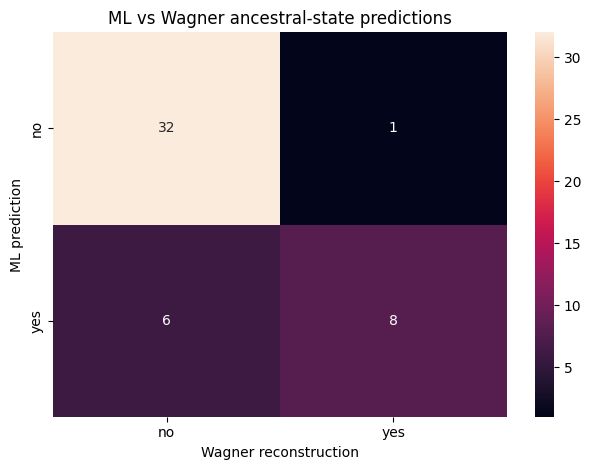

In [70]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["no", "yes"],
    yticklabels=["no", "yes"]
)

plt.xlabel("Wagner reconstruction")
plt.ylabel("ML prediction")
plt.title("ML vs Wagner ancestral-state predictions")
plt.tight_layout()
plt.show()

In [71]:
compare_df

,NodeName,sporulation,annot_or_predict,max_proba,proba_and_uncert,wagner_annotation,wagner_confidence,wagner_diderm_proba,wagner_monoderm_proba
1237,1237,yes,predict,0.987273,0.987273,yes,0.880797,0.119203,0.880797
1549,1549,yes,predict,0.976856,0.976856,yes,0.880797,0.119203,0.880797
1568,1568,yes,predict,0.520106,0.520106,yes,0.880797,0.119203,0.880797
1632,1632,no,predict,0.629497,0.370503,Ambiguous,0.500000,0.500000,0.500000
1651,1651,no,predict,0.997806,0.002194,no,0.880797,0.880797,0.119203
1657,1657,no,predict,0.957208,0.042792,no,0.880797,0.880797,0.119203
1700,1700,no,predict,0.997478,0.002522,no,0.880797,0.880797,0.119203
1749,1749,yes,predict,0.880415,0.880415,no,0.500000,0.500000,0.500000
1777,1777,no,predict,0.999247,0.000753,no,0.880797,0.880797,0.119203
1798,1798,no,predict,0.955103,0.044897,no,0.880797,0.880797,0.119203


In [72]:
agreement = (
    compare_df["sporulation"] == compare_df["wagner_annotation"]
).mean()

print(f"Agreement: {agreement:.1%}")

Agreement: 78.4%


In [73]:
from sklearn.metrics import matthews_corrcoef

# Only predicted ancestral nodes
compare_df = df_pred[
    (df_pred["annot_or_predict"] == "predict") &
    (df_pred["wagner_annotation"].notna())
].copy()

# Convert labels to 0/1
state_labels = {
    "no": 0,
    "yes": 1
}

y_ml = compare_df["sporulation"].map(state_labels)
y_wagner = compare_df["wagner_annotation"].map(state_labels)

# Remove any rows with unmapped labels
valid = y_ml.notna() & y_wagner.notna()

mcc = matthews_corrcoef(
    y_ml[valid],
    y_wagner[valid]
)

print("MCC:", mcc)
print("Number of ancestral nodes:", valid.sum())

MCC: 0.6289352956273975
Number of ancestral nodes: 47


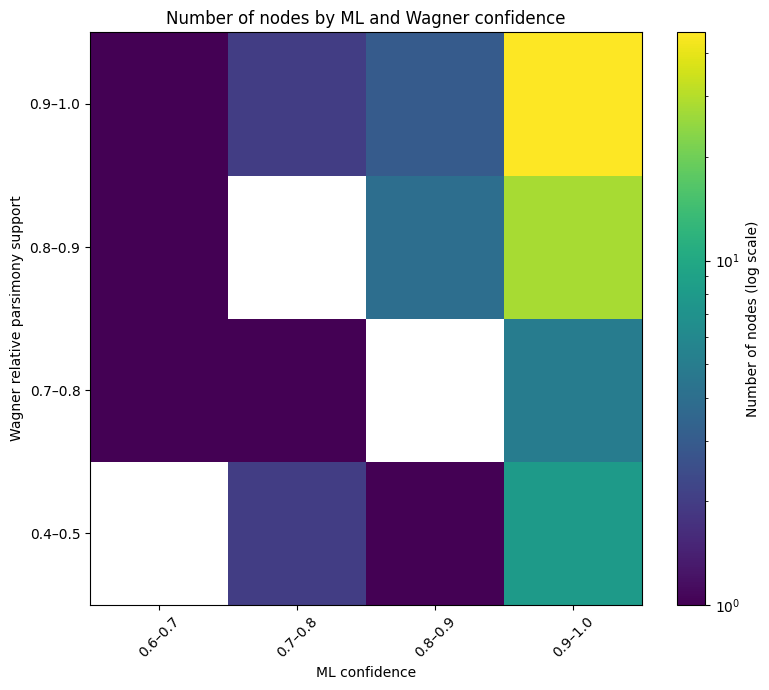

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

plot_df = df_pred.dropna(
    subset=["max_proba", "wagner_confidence"]
).copy()

bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5,
        0.6, 0.7, 0.8, 0.9, 1.0]

plot_df["ML_bin"] = pd.cut(
    plot_df["max_proba"], bins=bins, include_lowest=True
)

plot_df["Wagner_bin"] = pd.cut(
    plot_df["wagner_confidence"], bins=bins, include_lowest=True
)

counts = pd.crosstab(
    plot_df["Wagner_bin"],
    plot_df["ML_bin"]
)

# Replace zeros with NaN so they are not included in log scaling
counts_log = counts.replace(0, float("nan"))

plt.figure(figsize=(8, 7))

plt.imshow(
    counts_log,
    origin="lower",
    aspect="auto",
    norm=LogNorm(
        vmin=counts_log.min().min(),
        vmax=counts_log.max().max()
    )
)

plt.xticks(
    range(len(counts.columns)),
    [f"{b.left:.1f}–{b.right:.1f}" for b in counts.columns],
    rotation=45
)

plt.yticks(
    range(len(counts.index)),
    [f"{b.left:.1f}–{b.right:.1f}" for b in counts.index]
)

plt.xlabel("ML confidence")
plt.ylabel("Wagner relative parsimony support")
plt.title("Number of nodes by ML and Wagner confidence")

cbar = plt.colorbar()
cbar.set_label("Number of nodes (log scale)")

plt.tight_layout()
plt.show()